# Analisi generale dei dataset di personaggi

Questo notebook confronta i dataset di personaggi DC e Marvel per ottenere una panoramica generale dei dati disponibili: dimensioni, valori mancanti, distribuzione per identità, allineamento, genere, stato di vita e apparizioni.

Obiettivo del progetto: trasformare i dataset in una base di analisi strutturata, utile per capire come i personaggi sono rappresentati nei due universi e per preparare eventuali successive analisi su qualità dei dati, pulizia e modellazione dei contenuti.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

base = Path('/Users/marcogreco/ComicGraph/Dataset')
dc = pd.read_csv(base / 'PersonaggiDCFive.csv')
marvel = pd.read_csv(base / 'PersonaggiMarvelFive.csv')

# Normalizzazione colonne comuni
for df, brand in [(dc, 'DC'), (marvel, 'Marvel')]:
    df['brand'] = brand
    if 'Year' in df.columns:
        df.rename(columns={'Year': 'YEAR'}, inplace=True)
    if 'FIRST APPEARANCE' in df.columns:
        df['FIRST APPEARANCE'] = df['FIRST APPEARANCE'].astype(str)

# Pulizia base
for df in [dc, marvel]:
    df['APPEARANCES'] = pd.to_numeric(df['APPEARANCES'], errors='coerce')
    df['YEAR'] = pd.to_numeric(df['YEAR'], errors='coerce')

# Unione per confronto
combined = pd.concat([dc, marvel], ignore_index=True)

print('DC rows:', len(dc))
print('Marvel rows:', len(marvel))
print('DC columns:', list(dc.columns))
print('Marvel columns:', list(marvel.columns))


DC rows: 6896
Marvel rows: 16376
DC columns: ['page_id', 'name', 'urlslug', 'ID', 'ALIGN', 'EYE', 'HAIR', 'SEX', 'GSM', 'ALIVE', 'APPEARANCES', 'FIRST APPEARANCE', 'YEAR', 'brand']
Marvel columns: ['page_id', 'name', 'urlslug', 'ID', 'ALIGN', 'EYE', 'HAIR', 'SEX', 'GSM', 'ALIVE', 'APPEARANCES', 'FIRST APPEARANCE', 'YEAR', 'brand']


In [8]:
# Dimensioni e valori mancanti
summary = pd.DataFrame({
    'dataset': ['DC', 'Marvel'],
    'righe': [len(dc), len(marvel)],
    'colonne': [dc.shape[1], marvel.shape[1]],
    'valori_mancanti': [dc.isna().sum().sum(), marvel.isna().sum().sum()],
    'mancanti_per_colonna': [dc.isna().sum().to_dict(), marvel.isna().sum().to_dict()],
})
summary

,dataset,righe,colonne,valori_mancanti,mancanti_per_colonna
0,DC,6896,14,15969,"{'page_id': 0, 'name': 0, 'urlslug': 0, 'ID': ..."
1,Marvel,16376,14,40482,"{'page_id': 0, 'name': 0, 'urlslug': 0, 'ID': ..."


In [9]:
# Statistiche sulle apparizioni e sull'anno di prima comparsa
stats = pd.DataFrame({
    'dataset': ['DC', 'Marvel'],
    'apparizioni_media': [dc['APPEARANCES'].mean(), marvel['APPEARANCES'].mean()],
    'apparizioni_mediana': [dc['APPEARANCES'].median(), marvel['APPEARANCES'].median()],
    'apparizioni_massime': [dc['APPEARANCES'].max(), marvel['APPEARANCES'].max()],
    'prima_comp_anno_min': [dc['YEAR'].min(), marvel['YEAR'].min()],
    'prima_comp_anno_max': [dc['YEAR'].max(), marvel['YEAR'].max()],
})
stats

,dataset,apparizioni_media,apparizioni_mediana,apparizioni_massime,prima_comp_anno_min,prima_comp_anno_max
0,DC,23.625134,6.0,3093.0,1935.0,2013.0
1,Marvel,17.033377,3.0,4043.0,1939.0,2013.0


In [10]:
# Distribuzione per allineamento, sesso e stato di vita
for col in ['ALIGN', 'SEX', 'ALIVE']:
    print(f'\n=== {col} ===')
    print(dc[col].value_counts(dropna=False).head(10).to_string())
    print('---')
    print(marvel[col].value_counts(dropna=False).head(10).to_string())



=== ALIGN ===
ALIGN
Bad Characters        2895
Good Characters       2832
NaN                    601
Neutral Characters     565
Reformed Criminals       3
---
ALIGN
Bad Characters        6720
Good Characters       4636
NaN                   2812
Neutral Characters    2208

=== SEX ===
SEX
Male Characters           4783
Female Characters         1967
NaN                        125
Genderless Characters       20
Transgender Characters       1
---
SEX
Male Characters           11638
Female Characters          3837
NaN                         854
Agender Characters           45
Genderfluid Characters        2

=== ALIVE ===
ALIVE
Living Characters      5200
Deceased Characters    1693
NaN                       3
---
ALIVE
Living Characters      12608
Deceased Characters     3765
NaN                        3


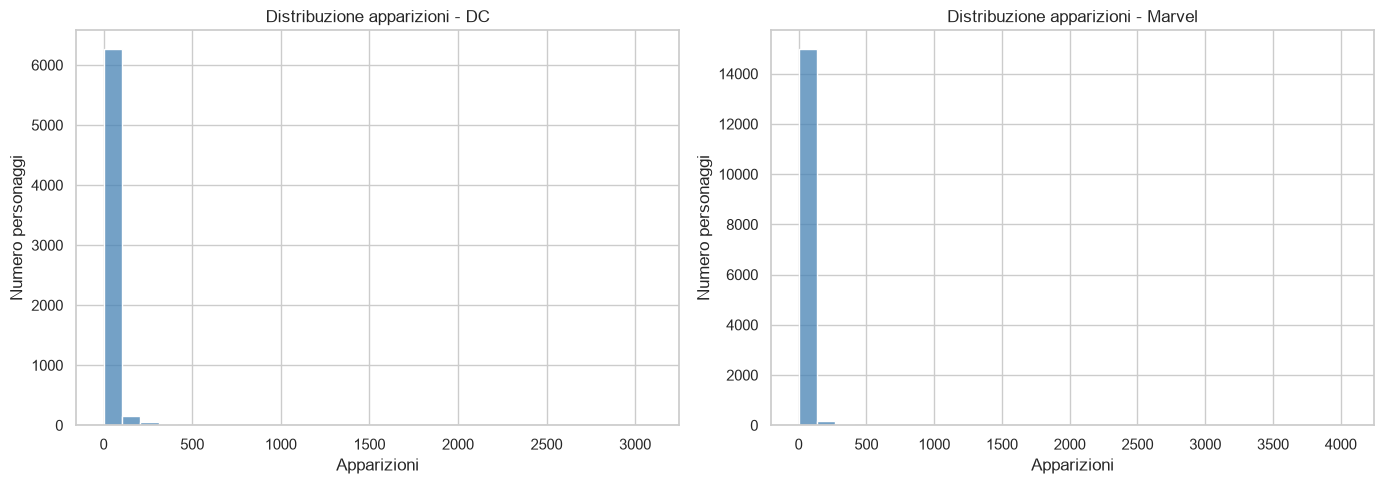

In [11]:
# Confronto visivo: apparizioni per brand
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, (df, label) in enumerate([(dc, 'DC'), (marvel, 'Marvel')]):
    sns.histplot(df['APPEARANCES'].dropna(), bins=30, ax=ax[i], color='steelblue')
    ax[i].set_title(f'Distribuzione apparizioni - {label}')
    ax[i].set_xlabel('Apparizioni')
    ax[i].set_ylabel('Numero personaggi')
plt.tight_layout()
plt.show()


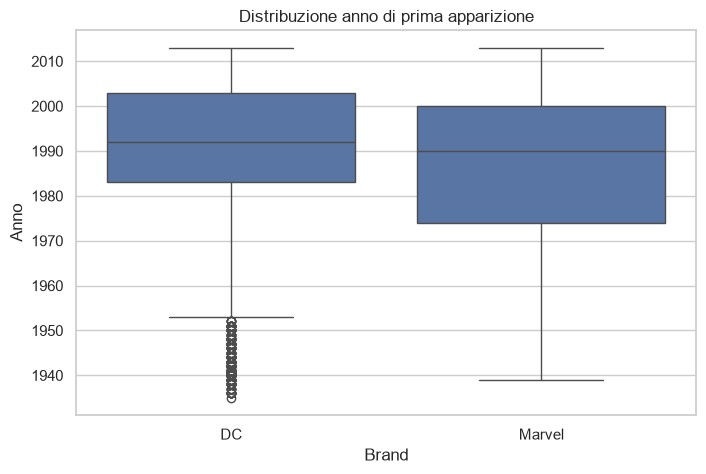

In [12]:
# Confronto visivo: anno di prima apparizione
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=combined, x='brand', y='YEAR', ax=ax)
ax.set_title('Distribuzione anno di prima apparizione')
ax.set_xlabel('Brand')
ax.set_ylabel('Anno')
plt.show()


## Osservazioni generali

- Marvel contiene più record rispetto a DC.
- Le colonne di testo mostrano valori mancanti significativi, in particolare per GSM e alcuni attributi come occhi, capelli e allineamento.
- Le apparizioni sono molto asimmetriche: pochi personaggi hanno numeri molto alti, mentre la maggior parte ha valori più bassi.
- Il confronto tra le distribuzioni di anno di prima apparizione e apparizioni può aiutare a capire come i due universi sono rappresentati nel dataset.

## Analisi dei valori mancanti

Questa sezione mostra in modo più dettagliato quali colonne presentano valori mancanti e quanto incidono sul dataset.

In [13]:
# Percentuale di valori mancanti per colonna
for name, df in [('DC', dc), ('Marvel', marvel)]:
    missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
    print(f'\n{name} - percentuale valori mancanti per colonna:')
    print(missing_pct[missing_pct > 0].to_string())



DC - percentuale valori mancanti per colonna:
GSM                 99.071926
EYE                 52.610209
HAIR                32.975638
ID                  29.190835
ALIGN                8.715197
APPEARANCES          5.147912
SEX                  1.812645
FIRST APPEARANCE     1.000580
YEAR                 1.000580
ALIVE                0.043503

Marvel - percentuale valori mancanti per colonna:
GSM                 99.450415
EYE                 59.642159
HAIR                26.038105
ID                  23.021495
ALIGN               17.171470
APPEARANCES          6.692721
SEX                  5.214949
FIRST APPEARANCE     4.976795
YEAR                 4.976795
ALIVE                0.018319


In [14]:
# Tabella riassuntiva dei valori mancanti
missing_summary = []
for name, df in [('DC', dc), ('Marvel', marvel)]:
    for col in df.columns:
        missing_count = int(df[col].isna().sum())
        if missing_count > 0:
            missing_summary.append({
                'dataset': name,
                'colonna': col,
                'valori_mancanti': missing_count,
                'percentuale': round((missing_count / len(df)) * 100, 2)
            })

missing_df = pd.DataFrame(missing_summary)
missing_df.sort_values(['dataset', 'valori_mancanti'], ascending=[True, False])

,dataset,colonna,valori_mancanti,percentuale
5,DC,GSM,6832,99.07
2,DC,EYE,3628,52.61
3,DC,HAIR,2274,32.98
0,DC,ID,2013,29.19
1,DC,ALIGN,601,8.72
7,DC,APPEARANCES,355,5.15
4,DC,SEX,125,1.81
8,DC,FIRST APPEARANCE,69,1.00
9,DC,YEAR,69,1.00
6,DC,ALIVE,3,0.04


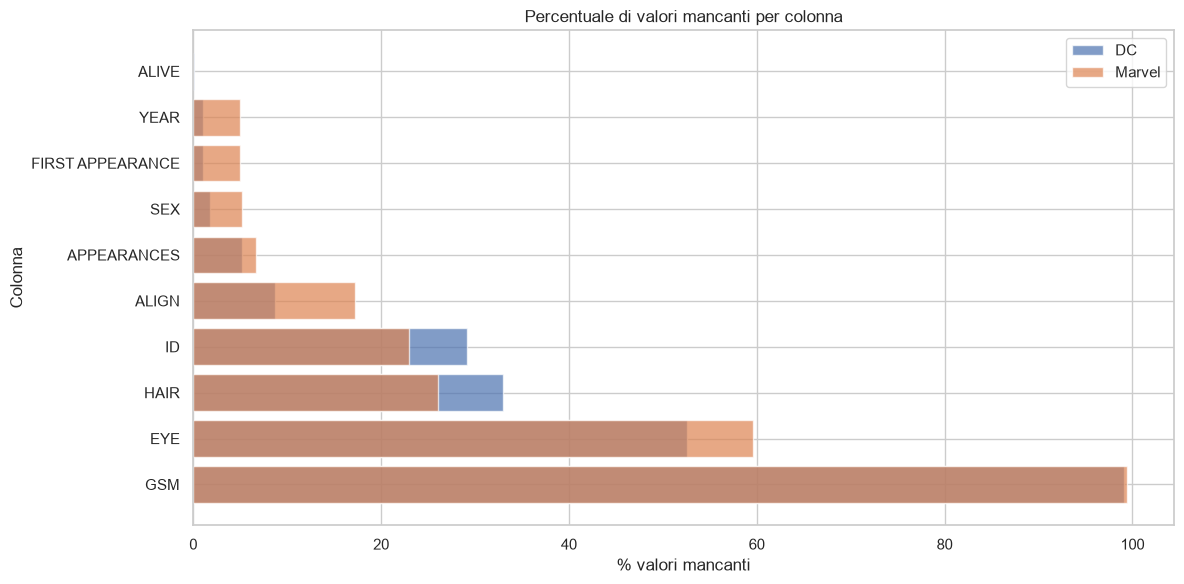

In [15]:
# Grafico dei valori mancanti più significativi
plt.figure(figsize=(12, 6))
for name, df in [('DC', dc), ('Marvel', marvel)]:
    missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
    missing_pct = missing_pct[missing_pct > 0]
    plt.barh(missing_pct.index, missing_pct.values, alpha=0.7, label=name)
plt.title('Percentuale di valori mancanti per colonna')
plt.xlabel('% valori mancanti')
plt.ylabel('Colonna')
plt.legend()
plt.tight_layout()
plt.show()